> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Módulo 51 | Regresión lineal múltiple mediante matrices
**Javier Bueno Sánchez · Profesión Científico de Datos**

**Objetivo:** pronosticar el precio de una vivienda del conjunto `kc_house_data.csv`. La validación se hace con un conjunto de prueba separado antes de seleccionar variables. Los precios y los errores se expresan en USD; las superficies figuran en pies cuadrados.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({'figure.figsize': (8, 4.6), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.labelcolor': '#263238'})
archivo = Path('kc_house_data.csv')
if not archivo.exists():
    archivo = Path('upload/kc_house_data.csv')
df = pd.read_csv(archivo)
print('Dimensiones:', df.shape, '| Faltantes:', int(df.isna().sum().sum()))
print('Precio mediano (USD):', f'{df.price.median():,.0f}')
print('Identificadores repetidos:', df.id.duplicated().sum())
display(df.head(3))

Dimensiones: (21613, 21) | Faltantes: 0
Precio mediano (USD): 450,000
Identificadores repetidos: 177


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062


## 1. Diseño de variables y partición
Se excluyen `id` (identificador, incluso con ventas repetidas), `date` (fecha que requeriría otro diseño temporal), `zipcode` (un código numérico no representa distancia), `yr_renovated` (el cero mezcla ausencia de renovación con fecha) y `sqft_above`/`sqft_basement` (identidad exacta `sqft_living = sqft_above + sqft_basement`). Conservo `lat` y `long` como indicadores aproximados de ubicación, sin interpretar sus coeficientes como efectos causales. La prueba mantiene el 20% de registros; la eliminación estadística se decide exclusivamente sobre entrenamiento.

In [3]:
assert (df.sqft_living == df.sqft_above + df.sqft_basement).all()
variables_iniciales = ['bedrooms','bathrooms','sqft_living','sqft_lot','floors',
                       'waterfront','view','condition','grade','yr_built',
                       'lat','long','sqft_living15','sqft_lot15']
train, test = train_test_split(df, test_size=0.20, random_state=42)
print('Entrenamiento:', len(train), '| Prueba:', len(test))
print('Variables iniciales:', variables_iniciales)

Entrenamiento: 17290 | Prueba: 4323
Variables iniciales: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


## 2. Selección sobre entrenamiento
Partimos de variables plausibles y retiramos iterativamente la que tenga el mayor valor p superior a 0,05 en el reporte OLS. Esta regla es didáctica, no prueba irrelevancia universal; los valores p posteriores a esta selección no deben tratarse como inferencia confirmatoria. `grade`, `condition` y `view` se aproximan como escalas lineales, otra limitación explícita.

In [5]:
variables = variables_iniciales.copy()
retiros = []
while True:
    reporte = sm.OLS(train.price, sm.add_constant(train[variables], has_constant='add')).fit()
    p = reporte.pvalues.drop('const')
    if p.max() <= 0.05:
        break
    candidata = p.idxmax()
    retiros.append((candidata, float(p.max())))
    variables.remove(candidata)
print('Retiradas (variable, valor p):', retiros)
print('Variables finales:', variables)
print('Rango de la matriz:', np.linalg.matrix_rank(sm.add_constant(train[variables]).to_numpy()),
      '| Columnas:', len(variables)+1)

Retiradas (variable, valor p): [('sqft_lot', 0.11955218756624278)]
Variables finales: ['bedrooms', 'bathrooms', 'sqft_living', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Rango de la matriz: 14 | Columnas: 14


## 3. Mínimos cuadrados con matrices
Con columna de unos para el intercepto, $X\in\mathbb{R}^{n	imes(k+1)}$ y $y\in\mathbb{R}^{n}$, se minimiza $\|y-Xeta\|_2^2$. Las ecuaciones normales son $X^	op X\hateta=X^	op y$. La solución se calcula con `np.linalg.lstsq(X, y)`, que aplica álgebra matricial numéricamente más estable que formar e invertir explícitamente $X^	op X$. Contrastamos las ecuaciones normales mediante su residuo relativo.

In [7]:
X = np.column_stack([np.ones(len(train)), train[variables].to_numpy(dtype=float)])
y = train.price.to_numpy(dtype=float)
beta, residuo_lstsq, rango, singulares = np.linalg.lstsq(X, y, rcond=None)
assert rango == X.shape[1], 'La matriz de diseño carece de rango completo.'
residuo_normal = np.linalg.norm(X.T @ (y - X @ beta)) / (np.linalg.norm(X.T @ y) + 1e-15)
coeficientes = pd.Series(beta, index=['const'] + variables, name='Matriz (USD)')
print('Residuo relativo de ecuaciones normales:', f'{residuo_normal:.3e}')
display(coeficientes.to_frame().round(3))

Residuo relativo de ecuaciones normales: 1.235e-13


,Matriz (USD)
const,-3.074013e+07
bedrooms,-3.342615e+04
bathrooms,4.432927e+04
sqft_living,1.668050e+02
floors,1.416362e+04
waterfront,5.778327e+05
view,4.828978e+04
condition,2.494324e+04
grade,9.856087e+04
yr_built,-2.682495e+03


## 4. Sumas de cuadrados y ajuste
Usamos la convención $TSS=\sum(y_i-ar y)^2$, $RSS=\sum(y_i-\hat y_i)^2$, $ESS=\sum(\hat y_i-ar y)^2$. Como el modelo contiene intercepto, $TSSpprox ESS+RSS$ (diferencias numéricas por redondeo). $R^2=1-RSS/TSS$ y $R^2_{aj}=1-(1-R^2)(n-1)/(n-k-1)$, con $k$ predictores.

In [9]:
ajuste_train = X @ beta
TSS = np.sum((y-y.mean())**2)
RSS = np.sum((y-ajuste_train)**2)
ESS = np.sum((ajuste_train-y.mean())**2)
n, k = len(y), len(variables)
r2_train = 1-RSS/TSS
r2_aj = 1-(1-r2_train)*(n-1)/(n-k-1)
print(f'TSS={TSS:.5e}; ESS={ESS:.5e}; RSS={RSS:.5e}')
print('Error relativo TSS-(ESS+RSS):', f'{abs(TSS-ESS-RSS)/TSS:.3e}')
print(f'R² entrenamiento={r2_train:.5f}; R² ajustado={r2_aj:.5f}')

TSS=2.25891e+15; ESS=1.56716e+15; RSS=6.91757e+14
Error relativo TSS-(ESS+RSS): 1.015e-13
R² entrenamiento=0.69377; R² ajustado=0.69354


## 5. Contraste con reporte automatizado
El reporte `statsmodels.OLS` usa la misma muestra y exactamente las mismas columnas. La comparación de coeficientes, R² y predicciones permite verificar la solución matricial. Los coeficientes indican cambios condicionales manteniendo los otros predictores constantes; no establecen causalidad.

In [11]:
comparacion = pd.DataFrame({'Matriz': coeficientes, 'statsmodels': reporte.params})
comparacion['Diferencia absoluta'] = (comparacion.Matriz-comparacion.statsmodels).abs()
display(comparacion.round(5))
print('Máxima diferencia de predicción en entrenamiento (USD):',
      f'{np.max(np.abs(ajuste_train-reporte.predict(sm.add_constant(train[variables], has_constant="add")))):.6f}')
print('Diferencia en R²:', f'{abs(r2_train-reporte.rsquared):.3e}')
print(reporte.summary())

Máxima diferencia de predicción en entrenamiento (USD): 0.000005
Diferencia en R²: 1.110e-16
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.694
Model:                            OLS   Adj. R-squared:                  0.694
Method:                 Least Squares   F-statistic:                     3011.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        11:04:33   Log-Likelihood:            -2.3558e+05
No. Observations:               17290   AIC:                         4.712e+05
Df Residuals:                   17276   BIC:                         4.713e+05
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

,Matriz,statsmodels,Diferencia absoluta
const,-3.074013e+07,-3.074013e+07,0.0
bedrooms,-3.342615e+04,-3.342615e+04,0.0
bathrooms,4.432927e+04,4.432927e+04,0.0
sqft_living,1.668049e+02,1.668049e+02,0.0
floors,1.416362e+04,1.416362e+04,0.0
waterfront,5.778327e+05,5.778327e+05,0.0
view,4.828978e+04,4.828978e+04,0.0
condition,2.494324e+04,2.494324e+04,0.0
grade,9.856087e+04,9.856087e+04,0.0
yr_built,-2.682495e+03,-2.682495e+03,0.0


## 6. Pronóstico fuera de muestra y diagnóstico
Las métricas de prueba se calculan sobre observaciones no usadas para ajustar ni seleccionar predictores. R² mide variación explicada respecto de predecir la media de la muestra evaluada; MAE y RMSE expresan el tamaño del error en USD. Revisamos también errores en el segmento de precio alto, donde un promedio global puede ocultar fallos.

Precio alto: umbral percentil 90 entrenamiento = USD 885,000; observaciones prueba = 447; MAE = USD 345,483


,Entrenamiento,Prueba
R²,0.694,0.694
MAE (USD),125471.290,128326.271
RMSE (USD),200022.767,214980.982


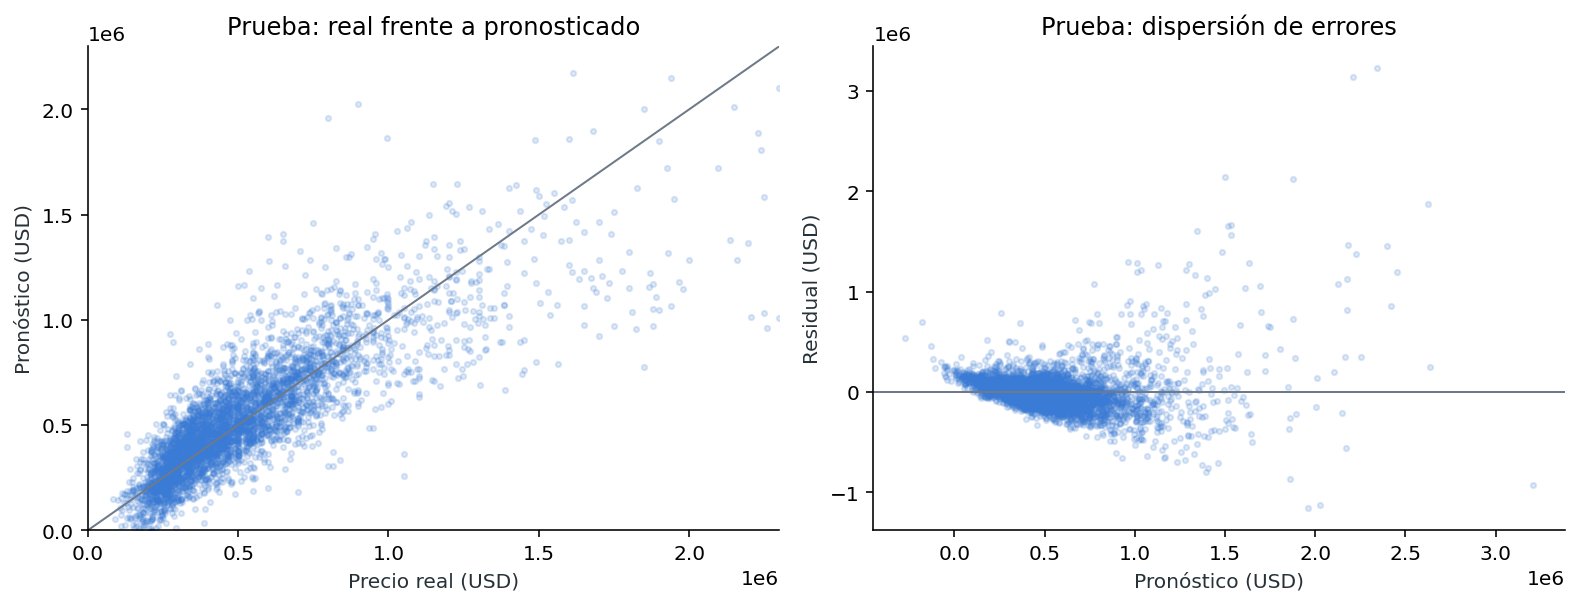

In [13]:
X_test = np.column_stack([np.ones(len(test)), test[variables].to_numpy(dtype=float)])
y_test = test.price.to_numpy(dtype=float)
pred = X_test @ beta
assert np.allclose(pred, reporte.predict(sm.add_constant(test[variables], has_constant='add')))
metricas = pd.DataFrame({'Entrenamiento': [r2_train, mean_absolute_error(y, ajuste_train), np.sqrt(mean_squared_error(y, ajuste_train))],
                         'Prueba': [r2_score(y_test,pred), mean_absolute_error(y_test,pred), np.sqrt(mean_squared_error(y_test,pred))]},
                        index=['R²', 'MAE (USD)', 'RMSE (USD)'])
display(metricas.round(3))
umbral = train.price.quantile(.90)
altas = y_test >= umbral
print(f'Precio alto: umbral percentil 90 entrenamiento = USD {umbral:,.0f};'
      f' observaciones prueba = {altas.sum()}; MAE = USD {mean_absolute_error(y_test[altas],pred[altas]):,.0f}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(y_test, pred, s=7, alpha=.17, color='#3A7BD5')
lim = np.percentile(np.r_[y_test,pred], 99.5)
axes[0].plot([0,lim],[0,lim], color='#6E7A89', lw=1)
axes[0].set(xlim=(0,lim), ylim=(0,lim), xlabel='Precio real (USD)', ylabel='Pronóstico (USD)', title='Prueba: real frente a pronosticado')
axes[1].scatter(pred, y_test-pred, s=7, alpha=.17, color='#3A7BD5')
axes[1].axhline(0, color='#6E7A89', lw=1)
axes[1].set(xlabel='Pronóstico (USD)', ylabel='Residual (USD)', title='Prueba: dispersión de errores')
fig.tight_layout()
plt.show()

## 7. Ecuación y lectura crítica
La ecuación final es $\widehat{precio}=\hateta_0+\sum_{j=1}^k\hateta_j x_j$, con los valores completos de la tabla de coeficientes. El signo negativo de `bedrooms` describe una asociación *condicional* a superficie, baños y calidad: no significa que quitar habitaciones aumente el precio. Las coordenadas están en grados; sus coeficientes por un grado no deben confundirse con un desplazamiento habitual dentro de un barrio. El modelo sirve como referencia estadística y requiere revisar valores extremos, relaciones no lineales, heterocedasticidad y ubicación antes de valorar una casa concreta. Esta tabla no es una serie temporal: la fecha se excluyó deliberadamente y una partición aleatoria no evalúa capacidad de pronóstico futuro.

In [15]:
ejemplo = test.iloc[[0]][variables]
precio_estimado = float(np.r_[1.0, ejemplo.iloc[0].to_numpy(dtype=float)] @ beta)
print('Ejemplo reservado del conjunto de prueba:')
display(ejemplo)
print(f'Precio real: USD {test.iloc[0].price:,.0f} | Pronóstico: USD {precio_estimado:,.0f}')
print('Ecuación final (USD):')
print('precio_estimado = ' + ' '.join(f'{v:+.6f}*{name}' for name,v in coeficientes.items()))

Ejemplo reservado del conjunto de prueba:
Precio real: USD 365,000 | Pronóstico: USD 465,553
Ecuación final (USD):
precio_estimado = -30740132.654595*const -33426.151193*bedrooms +44329.267200*bathrooms +166.804890*sqft_living +14163.617492*floors +577832.737594*waterfront +48289.777165*view +24943.240242*condition +98560.873870*grade -2682.495432*yr_built +543134.158580*lat -77536.416573*long +28.992558*sqft_living15 -0.222934*sqft_lot15


,bedrooms,bathrooms,sqft_living,floors,waterfront,view,condition,grade,yr_built,lat,long,sqft_living15,sqft_lot15
735,4,2.25,2070,2.0,0,0,4,8,1986,47.4388,-122.162,2390,7700
